# Autóeladási árak előrejelzésének kezdeti kutatási lépése

## Feltáró adatelemzés (EDA)

Ez a notebook a kutatás első, reprodukálható munkaváltozata. A cél annak feltárása, hogy az autók **eladási ára** milyen kapcsolatban áll a rendelkezésre álló jellemzőkkel, illetve milyen adat-előkészítésre lesz szükség a későbbi prediktív modellezés előtt.

A notebook fő kérdései:

1. Milyen szerkezetű és minőségű az adathalmaz?
2. Hogyan értelmezhetők az egyes változók, és milyen új változók képezhetők belőlük?
3. Milyen eloszlása van az árnak, és milyen különbségek láthatók márka, modell, üzemanyag-típus, kor, futásteljesítmény és motor-méret szerint?
4. Mely változók lehetnek hasznos kiindulópontok a későbbi ár-előrejelző modellben?

Az ábrák leíró jellegűek: együttmozgást és csoportkülönbségeket mutatnak, nem oksági hatásokat.

## 1. Könyvtárak és megjelenítési beállítások

A kód úgy készült, hogy a notebook és a `car_sales_data.csv` ugyanabban a mappában legyen. Ezért a fájl relatív útvonalról tölthető be, és a notebook könnyen újrafuttatható.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
DATA_PATH = Path("car_sales_data.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"A dataset nem található: {DATA_PATH.resolve()}")

## 2. Az adathalmaz betöltése és alapstruktúrája

A fájl pontosvesszővel tagolt CSV. A motor-méret tizedeselválasztója vessző, ezért a betöltéskor ezt ponttá alakítjuk a numerikus változó képzéséhez. Az eredeti szöveges oszlopot is megtartjuk, hogy az átalakítás ellenőrizhető legyen.

In [2]:
df = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig")
required_columns = ["Manufacturer", "Model", "Engine size", "Fuel type", "Year of manufacture", "Mileage", "Price"]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Hiányzó oszlop(ok): {missing_columns}")

df["Engine size (L)"] = pd.to_numeric(df["Engine size"].astype(str).str.strip().str.replace(",", ".", regex=False), errors="coerce")
reference_year = int(df["Year of manufacture"].max()) + 1
df["Car age"] = reference_year - df["Year of manufacture"]
df["Log price"] = np.log1p(df["Price"])
df["Mileage per year"] = df["Mileage"] / df["Car age"].clip(lower=1)
display(df.head())
print(f"Megfigyelések száma: {len(df):,}".replace(",", " "))
print(f"Változók száma az új változókkal együtt: {df.shape[1]}")
print(f"Referenciaév a kor számításához: {reference_year}")

,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price,Engine size (L),Car age,Log price,Mileage per year
0,Ford,Fiesta,"1,0",Petrol,2002,127300,3074,1.0,21,8.031060,6061.904762
1,Porsche,718 Cayman,"4,0",Petrol,2016,57850,49704,4.0,7,10.813861,8264.285714
2,Ford,Mondeo,"1,6",Diesel,2014,39190,24072,1.6,9,10.088846,4354.444444
3,Toyota,RAV4,"1,8",Hybrid,1988,210814,1705,1.8,35,7.441907,6023.257143
4,VW,Polo,"1,0",Petrol,2006,127869,4101,1.0,17,8.319230,7521.705882


Megfigyelések száma: 50 000
Változók száma az új változókkal együtt: 11
Referenciaév a kor számításához: 2023


## 3. Változók értelmezése

| Változó | Típus | Szerep / értelmezés |
|---|---|---|
| `Manufacturer` | kategorikus | A gyártó márkája; várhatóan erős csoportosító változó. |
| `Model` | kategorikus | A konkrét modell; magasabb részletességű, mint a márka. |
| `Engine size` | szöveges forrásmező | Tizedesvesszős literérték; a `Engine size (L)` numerikus változóban használjuk. |
| `Fuel type` | kategorikus | Benzin, dízel vagy hibrid; technológiai és piaci különbségeket jelezhet. |
| `Year of manufacture` | numerikus/diszkrét | A gyártási év; ebből képezzük az autó korát. |
| `Mileage` | numerikus | A futásteljesítmény; az ár várhatóan kapcsolatban áll vele. |
| `Price` | numerikus célváltozó | Az előrejelzendő eladási ár. |
| `Car age` | képzett numerikus | Az autó kora a referenciaévhez képest. |
| `Mileage per year` | képzett numerikus | A futásteljesítmény évesített közelítése. |
| `Log price` | képzett változó | Az ár ferdeségének csökkentésére használható. |

A képzett változók a meglévő mezők alternatív, elemzéshez hasznos reprezentációi.

## 4. Kezdeti adatminőségi audit

Az audit ellenőrzi a méretet, a hiányzó értékeket, a duplikációkat, az adattípusokat és a numerikus tartományokat. A szélsőértékek önmagukban nem feltétlenül hibák, ezért azokat külön vizualizációkkal is megvizsgáljuk.

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(dropna=False),
}).sort_values(["missing", "unique"], ascending=[False, True])
display(quality)
print(f"Teljesen duplikált sorok száma: {df.duplicated().sum():,}".replace(",", " "))
num_cols = ["Engine size (L)", "Year of manufacture", "Car age", "Mileage", "Mileage per year", "Price"]
numeric_summary = df[num_cols].describe().T
numeric_summary["skew"] = df[num_cols].skew()
display(numeric_summary.round(1))

,dtype,missing,missing_%,unique
Fuel type,str,0,0.0,3
Manufacturer,str,0,0.0,5
Engine size,str,0,0.0,14
Engine size (L),float64,0,0.0,14
Model,str,0,0.0,15
Year of manufacture,int64,0,0.0,39
Car age,int64,0,0.0,39
Price,int64,0,0.0,25045
Log price,float64,0,0.0,25045
Mileage,int64,0,0.0,44971


Teljesen duplikált sorok száma: 12


,count,mean,std,min,25%,50%,75%,max,skew
Engine size (L),50000.0,1.8,0.7,1.0,1.4,1.6,2.0,5.0,2.1
Year of manufacture,50000.0,2004.2,9.6,1984.0,1996.0,2004.0,2012.0,2022.0,-0.1
Car age,50000.0,18.8,9.6,1.0,11.0,19.0,27.0,39.0,0.1
Mileage,50000.0,112497.3,71632.5,630.0,54352.2,100987.5,158601.0,453537.0,0.7
Mileage per year,50000.0,5986.2,2002.9,500.0,4635.0,5995.9,7338.0,13865.6,0.0
Price,50000.0,13828.9,16416.7,76.0,3060.8,7971.5,19026.5,168081.0,2.9


### Adatminőségi értelmezés

- A szükséges mezők kitöltöttek, és a CSV minden sora azonos szerkezetű.
- A `Engine size` átalakítása után minden motor-méret numerikusan értelmezhető.
- Az ár és a futásteljesítmény ferdeségét érdemes figyelembe venni: a szélsőértékek a későbbi modell hibamértékeit befolyásolhatják.
- A duplikációk vizsgálata fontos, de az azonos értékű autók nem feltétlenül jelentik ugyanannak a rekordnak a többszörözését.

## 5. A célváltozó: az eladási ár eloszlása

Az ábra a célváltozó szintjét és log-transzformált változatát mutatja. A logaritmikus változat segíthet a ferde eloszlás és a magas árú megfigyelések hatásának értelmezésében.

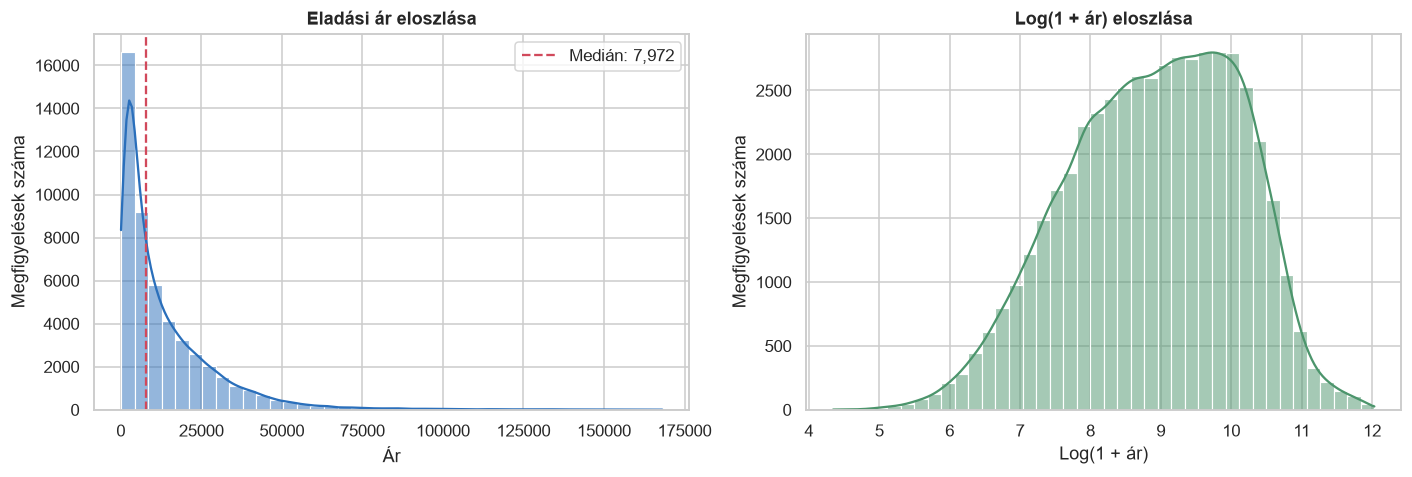

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["Price"], bins=40, kde=True, color="#2a6fbb", ax=axes[0])
axes[0].axvline(df["Price"].median(), color="#d1495b", linestyle="--", label=f"Medián: {df['Price'].median():,.0f}")
axes[0].set_title("Eladási ár eloszlása"); axes[0].set_xlabel("Ár"); axes[0].set_ylabel("Megfigyelések száma"); axes[0].legend()
sns.histplot(df["Log price"], bins=40, kde=True, color="#4c956c", ax=axes[1])
axes[1].set_title("Log(1 + ár) eloszlása"); axes[1].set_xlabel("Log(1 + ár)"); axes[1].set_ylabel("Megfigyelések száma")
plt.tight_layout(); plt.show()

## 6. Kategorikus változók és csoportkülönbségek

A darabszámok megmutatják, hogy mennyire kiegyensúlyozottak a kategóriák. A boxplotok a csoportok ár-eloszlásait hasonlítják össze; a kiugró pontokat elrejtjük, hogy 50 000 rekord mellett is olvasható maradjon az ábra.

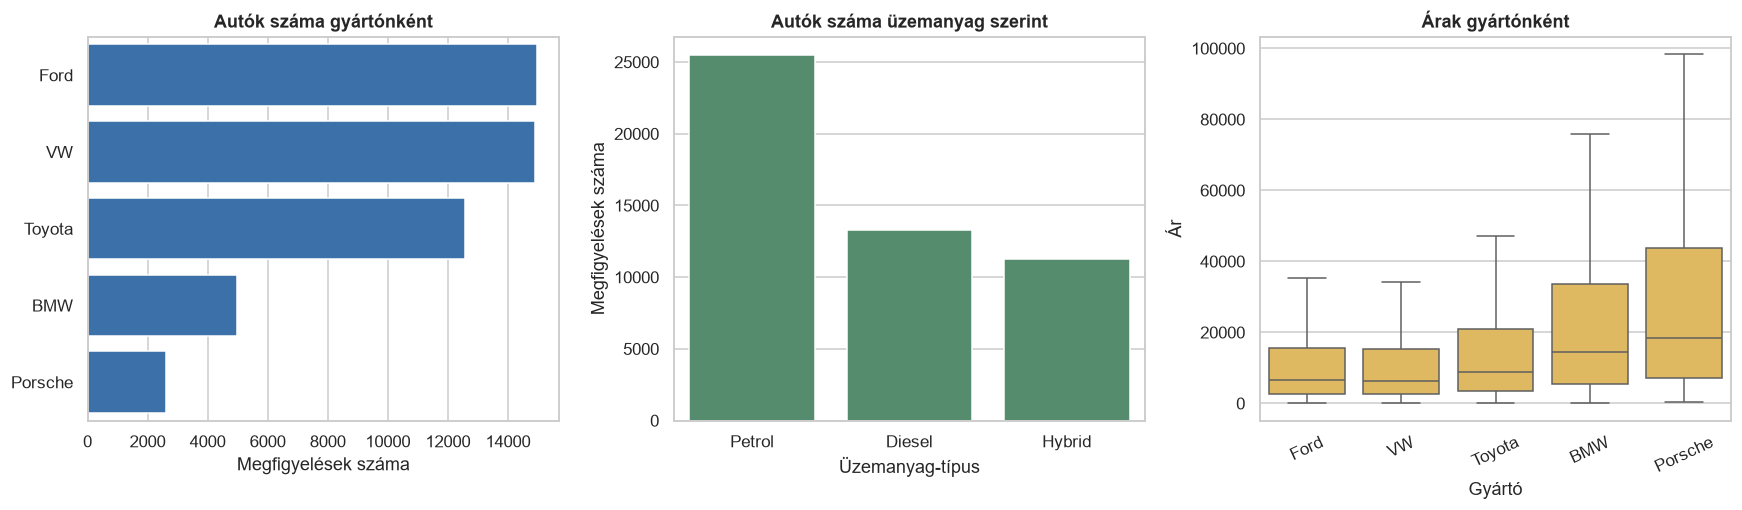

,count,median_price,mean_price
Manufacturer,,,
Porsche,2609,18441.0,29103.8
BMW,4965,14384.0,24429.5
Toyota,12554,8802.0,14340.4
Ford,14959,6646.0,10672.3
VW,14913,6428.0,10363.1


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
manufacturer_order = df["Manufacturer"].value_counts().index
sns.countplot(data=df, y="Manufacturer", order=manufacturer_order, color="#2a6fbb", ax=axes[0])
axes[0].set_title("Autók száma gyártónként"); axes[0].set_xlabel("Megfigyelések száma"); axes[0].set_ylabel("")
fuel_order = df["Fuel type"].value_counts().index
sns.countplot(data=df, x="Fuel type", order=fuel_order, color="#4c956c", ax=axes[1])
axes[1].set_title("Autók száma üzemanyag szerint"); axes[1].set_xlabel("Üzemanyag-típus"); axes[1].set_ylabel("Megfigyelések száma")
sns.boxplot(data=df, x="Manufacturer", y="Price", order=manufacturer_order, color="#f2c14e", showfliers=False, ax=axes[2])
axes[2].set_title("Árak gyártónként"); axes[2].set_xlabel("Gyártó"); axes[2].set_ylabel("Ár"); axes[2].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()
manufacturer_summary = df.groupby("Manufacturer")["Price"].agg(count="size", median_price="median", mean_price="mean").sort_values("median_price", ascending=False)
display(manufacturer_summary.round(1))

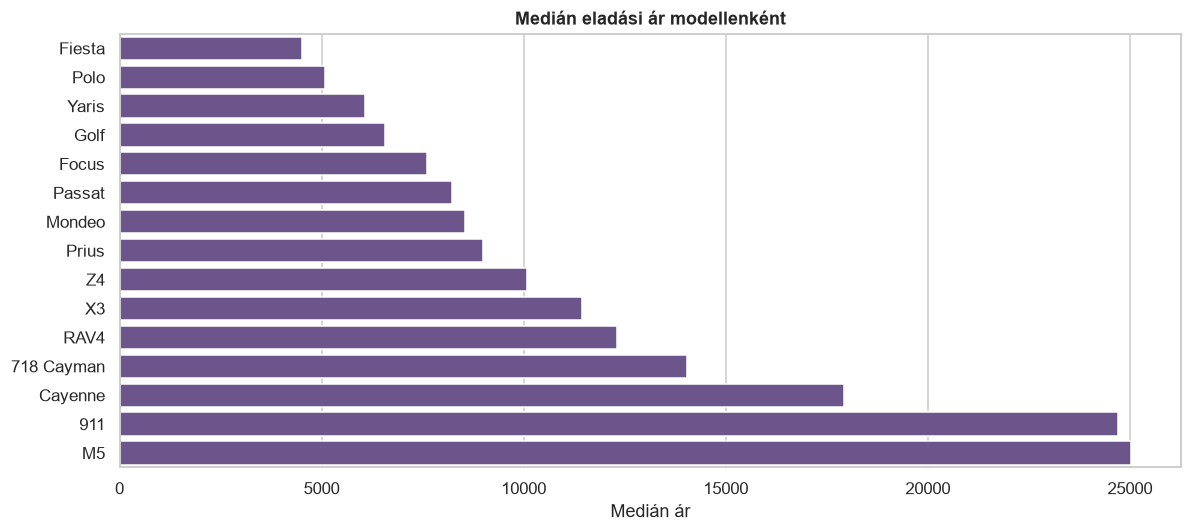

,count,median_price
Model,,
M5,1645,25022.0
911,872,24706.5
Cayenne,870,17936.5
718 Cayman,867,14031.0
RAV4,4292,12305.0
X3,1632,11448.5
Z4,1688,10082.5
Prius,4171,8989.0
Mondeo,5058,8543.5


In [6]:
model_summary = df.groupby("Model")["Price"].agg(count="size", median_price="median").sort_values("median_price", ascending=False)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=model_summary.sort_values("median_price").reset_index(), y="Model", x="median_price", color="#6a4c93", ax=ax)
ax.set_title("Medián eladási ár modellenként"); ax.set_xlabel("Medián ár"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
display(model_summary.round(1))

## 7. Numerikus változók és az ár kapcsolata

A pontdiagramok a legfontosabb numerikus magyarázó változók és az ár kapcsolatát mutatják. A színezés az üzemanyag-típust jelöli, így csoportonként eltérő mintázatok is láthatóvá válhatnak. Ezek leíró ábrák, nem végleges regressziós eredmények.

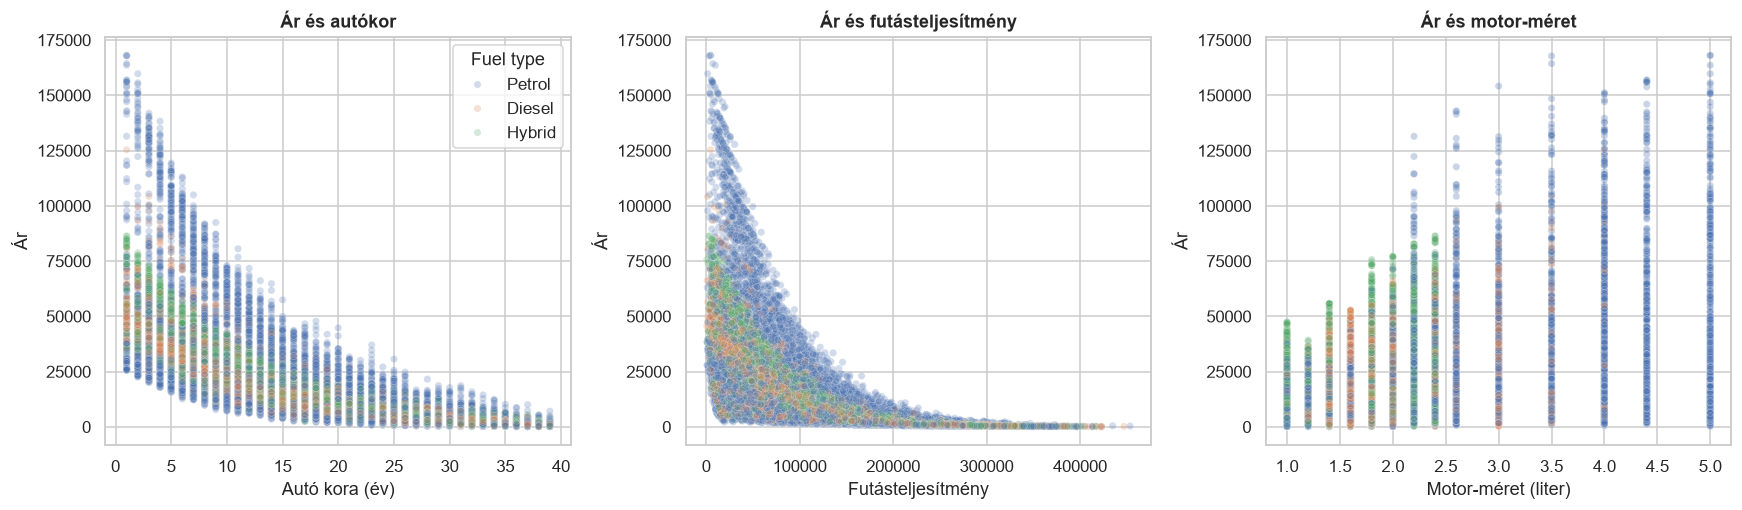

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sns.scatterplot(data=df, x="Car age", y="Price", hue="Fuel type", alpha=0.25, s=22, ax=axes[0])
axes[0].set_title("Ár és autókor"); axes[0].set_xlabel("Autó kora (év)"); axes[0].set_ylabel("Ár")
sns.scatterplot(data=df, x="Mileage", y="Price", hue="Fuel type", alpha=0.25, s=22, legend=False, ax=axes[1])
axes[1].set_title("Ár és futásteljesítmény"); axes[1].set_xlabel("Futásteljesítmény"); axes[1].set_ylabel("Ár")
sns.scatterplot(data=df, x="Engine size (L)", y="Price", hue="Fuel type", alpha=0.3, s=22, legend=False, ax=axes[2])
axes[2].set_title("Ár és motor-méret"); axes[2].set_xlabel("Motor-méret (liter)"); axes[2].set_ylabel("Ár")
plt.tight_layout(); plt.show()

## 8. Korrelációs áttekintés

A Pearson-korreláció numerikus változók lineáris együttmozgását méri. Kategorikus változókat nem tartalmaz, és nem bizonyít oksági kapcsolatot. Emiatt ezt az ábrát csak iránytűként használjuk; a kategorikus változók hatását a csoportos ábrák egészítik ki.

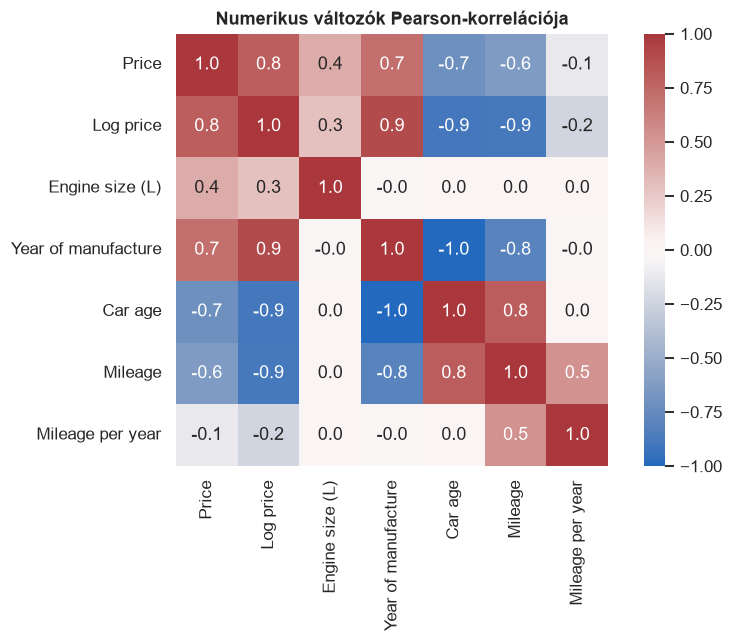

,korreláció az árral
Log price,0.8
Year of manufacture,0.7
Car age,-0.7
Mileage,-0.6
Engine size (L),0.4
Mileage per year,-0.1


In [8]:
correlation_columns = ["Price", "Log price", "Engine size (L)", "Year of manufacture", "Car age", "Mileage", "Mileage per year"]
corr = df[correlation_columns].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".1f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Numerikus változók Pearson-korrelációja")
plt.tight_layout(); plt.show()
display(corr["Price"].drop("Price").sort_values(key=lambda s: s.abs(), ascending=False).to_frame("korreláció az árral").round(1))

## 9. Többváltozós nézet: gyártó és üzemanyag-típus

Az egyetlen csoportosítás könnyen elrejthet összetett mintázatokat. Ezért a következő ábra a gyártó és az üzemanyag-típus együttes csoportjait mutatja mediánárral. A medián kevésbé érzékeny a szélsőséges árakra, mint az átlag.

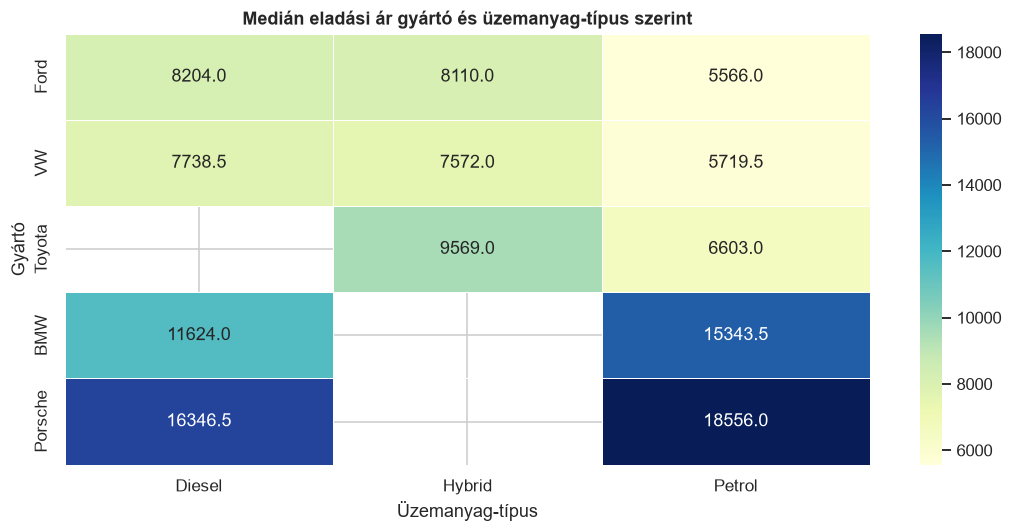

Fuel type,Diesel,Hybrid,Petrol
Manufacturer,,,
Ford,8204.0,8110.0,5566.0
VW,7738.5,7572.0,5719.5
Toyota,NaN,9569.0,6603.0
BMW,11624.0,NaN,15343.5
Porsche,16346.5,NaN,18556.0


In [9]:
median_table = df.pivot_table(index="Manufacturer", columns="Fuel type", values="Price", aggfunc="median").reindex(index=manufacturer_order)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(median_table, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5, ax=ax)
ax.set_title("Medián eladási ár gyártó és üzemanyag-típus szerint"); ax.set_xlabel("Üzemanyag-típus"); ax.set_ylabel("Gyártó")
plt.tight_layout(); plt.show(); display(median_table.round(1))

## 10. Kezdeti értelmezés és a következő kutatási lépések

### Mit mondhatunk felelősen az EDA alapján?

- Az adathalmaz jól strukturált, minden szükséges oszlop kitöltött, és a motor-méret numerikusan előállítható.
- Az ár, a futásteljesítmény és az autó kora természetes jelöltek a predikciós modellben.
- A gyártó, a modell és az üzemanyag-típus kategorikus változóként kerülhet be; ezeket megfelelő kódolással kell kezelni.
- A változók együttes hatása fontos lehet, ezért a csak egyváltozós korreláció nem elégséges.
- A szélsőértékeket nem töröltük automatikusan. A későbbi modellezés előtt meg kell határozni, hogy valódi ritka esetekről vagy adatminőségi hibákról van-e szó.

### Javasolt következő lépések

1. A célváltozó és a prediktorok véglegesítése, különösen a `Price` és `Log price` közül a modellezési célhoz illeszkedő választás.
2. Tanító-, validációs- és teszthalmaz létrehozása rögzített random seeddel.
3. Kategorikus változók kódolása és baseline modellek felállítása.
4. Egy egyszerű lineáris és egy nemlineáris fa-alapú modell összehasonlítása.
5. A teljesítmény MAE, RMSE és R² mutatókkal való értékelése.
6. A modellmagyarázat és a reziduális hibák vizsgálata, különös tekintettel a ritka modellekre és a szélsőséges árakra.

A jelenlegi notebook a modellépítés előtti adatértelmezési és EDA-szakaszt zárja le; prediktív teljesítményre vonatkozó állítást még nem tesz.